# Modelling

## 1. Setup & Preparation

### 1.1. Loading Libraries

In [4]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import r2_score, root_mean_squared_error # <-- Import the new function
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor

### 1.2. Loading Dataset

In [6]:
analysis_ready_path = '/Users/callumhall/Documents/Dissertation/Datasets/analysis_gdf.gpkg'
analysis_gdf = gpd.read_file(analysis_ready_path)

### 1.3. Define Features & Target

In [8]:
# The target variable is the SAMHI Score.
# The features are all the other socio-economic and environmental variables.
features = [
    'distance_to_greenspace', 
    'greenspace_area_in_1000m',
    'greenspace_area_in_500m',
    'Pct_Edu_Level_4_Plus',
    'Pct_Tenure_Private_Rented',
    'Pct_Occ_High_Skill',
    'Pct_Age_Young_Adults',
    'Pct_Ethnic_White',
    'Pct_Ethnic_Asian',
    'Pct_Ethnic_Black',
    'Pct_Ethnic_Mixed',
    'Crime_Rate_per_1000',
    'HPI_Change_pct',
    'Income_Deprivation_Score',
    'Pct_Flats'
]
target = 'SAMHI_Score'

X = analysis_gdf[features]
y = analysis_gdf[target]

### 1.4. Split into Training & Testing

In [10]:
# We use a 70/30 split. random_state ensures the split is the same every time.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"\nData split into {len(X_train)} training rows and {len(X_test)} testing rows.")


Data split into 3363 training rows and 1442 testing rows.


## 2. Model Training & Evaluation

### 2.1. Initialising & Training RF Regressor

In [13]:
# n_estimators=100 is a good starting point. n_jobs=-1 uses all available CPU cores.
print("\nTraining the Random Forest model...")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Model training complete.")


Training the Random Forest model...
Model training complete.


### 2.2. Predictions

In [15]:
print("\n--- Model Evaluation ---")
y_pred = rf_model.predict(X_test)

# Calculate R-squared (this line is unchanged)
r2 = r2_score(y_test, y_pred)

# THE FIX: Use the new root_mean_squared_error function
rmse = root_mean_squared_error(y_test, y_pred)

print(f"R-squared (R²): {r2:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")


--- Model Evaluation ---
R-squared (R²): 0.50
Root Mean Squared Error (RMSE): 0.39


### 2.3. Hyperparameter Tuning

In [17]:
# --- 1. Define the grid of parameters to test ---
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 2, 4]
}

# --- 2. Set up the Grid Search ---
# cv=5 means it will use 5-fold cross-validation
grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42), 
                           param_grid=param_grid, 
                           cv=5, 
                           n_jobs=-1, 
                           verbose=2)

# --- 3. Run the Grid Search on your training data ---
# This can take some time to run
grid_search.fit(X_train, y_train)

# --- 4. Get the best parameters and evaluate the new model ---
print("\nBest parameters found:", grid_search.best_params_)
best_rf_model = grid_search.best_estimator_
y_pred_tuned = best_rf_model.predict(X_test)
r2_tuned = r2_score(y_test, y_pred_tuned)

print(f"Original R-squared: 0.50")
print(f"Tuned R-squared: {r2_tuned:.2f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits

Best parameters found: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 300}
Original R-squared: 0.50
Tuned R-squared: 0.50


### 2.4. Adding Interaction Terms

In [19]:
# --- 1. Standardize the two features to be interacted ---
# This ensures they are on a comparable scale before multiplication
scaler = StandardScaler()
analysis_gdf[['greenspace_area_in_1000m', 'Income_Deprivation_Score']] = scaler.fit_transform(
    analysis_gdf[['greenspace_area_in_1000m', 'Income_Deprivation_Score']]
)

# --- 2. Create the interaction term ---
analysis_gdf['greenspace_x_deprivation'] = analysis_gdf['greenspace_area_in_1000m'] * analysis_gdf['Income_Deprivation_Score']
print("Interaction feature 'greenspace_x_deprivation' created.")

# --- 3. Re-run your model with this new feature included ---
# Add 'greenspace_x_deprivation' to your list of features
features_with_interaction = features + ['greenspace_x_deprivation']
X_interaction = analysis_gdf[features_with_interaction]
y = analysis_gdf[target]

# Split and train again
X_train_int, X_test_int, y_train_int, y_test_int = train_test_split(X_interaction, y, test_size=0.3, random_state=42)
rf_model_int = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model_int.fit(X_train_int, y_train_int)

# Evaluate the new model
y_pred_int = rf_model_int.predict(X_test_int)
r2_int = r2_score(y_test_int, y_pred_int)

print(f"\nOriginal R-squared: 0.50")
print(f"R-squared with Interaction Term: {r2_int:.2f}")

Interaction feature 'greenspace_x_deprivation' created.

Original R-squared: 0.50
R-squared with Interaction Term: 0.50


### 2.5. XGBoost

In [21]:
# --- 1. Train the Gradient Boosting model on your original features ---
print("\n--- Training Gradient Boosting model ---")
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
gb_model.fit(X_train, y_train) # Using the original X_train and y_train

# --- 2. Evaluate its performance ---
y_pred_gb = gb_model.predict(X_test)
r2_gb = r2_score(y_test, y_pred_gb)

print(f"Random Forest R-squared: 0.50")
print(f"Gradient Boosting R-squared: {r2_gb:.2f}")


--- Training Gradient Boosting model ---
Random Forest R-squared: 0.50
Gradient Boosting R-squared: 0.52


### 2.7. Hyperparameter Tuning XGBoost

In [23]:
# --- 1. Define the grid of parameters to test ---
# This is a smaller grid to run faster, you can expand it
param_grid_gb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [5, 10],
    'min_samples_leaf': [2, 4]
}

# --- 2. Set up the Grid Search ---
grid_search_gb = GridSearchCV(estimator=GradientBoostingRegressor(random_state=42), 
                              param_grid=param_grid_gb, 
                              cv=5, 
                              n_jobs=-1, 
                              verbose=2)

# --- 3. Run the Grid Search on your training data ---
print("Tuning Gradient Boosting model...")
grid_search_gb.fit(X_train, y_train)

# --- 4. Get the best parameters and evaluate the new model ---
print("\nBest parameters found:", grid_search_gb.best_params_)
best_gb_model = grid_search_gb.best_estimator_
y_pred_tuned_gb = best_gb_model.predict(X_test)
r2_tuned_gb = r2_score(y_test, y_pred_tuned_gb)

print(f"\nOriginal Gradient Boosting R-squared: 0.52")
print(f"Tuned Gradient Boosting R-squared: {r2_tuned_gb:.2f}")

Tuning Gradient Boosting model...
Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best parameters found: {'learning_rate': 0.05, 'max_depth': 5, 'min_samples_leaf': 4, 'n_estimators': 200}

Original Gradient Boosting R-squared: 0.52
Tuned Gradient Boosting R-squared: 0.53


In [24]:
# --- 1. Create a copy of your feature set for this experiment ---
X_log = X.copy()

# --- 2. Identify skewed columns and apply a log transform ---
# np.log1p(x) calculates log(1+x), which safely handles zero values.
skewed_cols = ['greenspace_area_in_500m', 'greenspace_area_in_1000m', 'Crime_Rate_per_1000']
for col in skewed_cols:
    X_log[col] = np.log1p(X_log[col])

# --- 3. Re-run your best model with the transformed features ---
# Use the best model from the hyperparameter tuning (e.g., best_gb_model)
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X_log, y, test_size=0.3, random_state=42)
best_gb_model.fit(X_train_log, y_train_log)
y_pred_log = best_gb_model.predict(X_test_log)
r2_log = r2_score(y_test_log, y_pred_log)

print(f"\nTuned Gradient Boosting R-squared: {r2_tuned_gb:.2f}")
print(f"R-squared with Log-Transformed Features: {r2_log:.2f}")


Tuned Gradient Boosting R-squared: 0.53
R-squared with Log-Transformed Features: 0.53


In [25]:
# This will show you the average value and the spread of your target variable
print(analysis_gdf['SAMHI_Score'].describe())

count    4805.000000
mean       -0.267790
std         0.538761
min        -2.256648
25%        -0.626233
50%        -0.306716
75%         0.035153
max         4.671870
Name: SAMHI_Score, dtype: float64


## 3. Feature Importance - Interpretation

### 3.1. Extract Feature Importances from Trained Model

In [28]:
print("\n--- Feature Importances ---")
importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_importance_df)


--- Feature Importances ---
                      Feature  Importance
13   Income_Deprivation_Score    0.188958
4   Pct_Tenure_Private_Rented    0.183876
8            Pct_Ethnic_Asian    0.102369
7            Pct_Ethnic_White    0.088314
3        Pct_Edu_Level_4_Plus    0.069880
11        Crime_Rate_per_1000    0.052480
14                  Pct_Flats    0.042323
12             HPI_Change_pct    0.038899
10           Pct_Ethnic_Mixed    0.038620
5          Pct_Occ_High_Skill    0.036726
9            Pct_Ethnic_Black    0.033319
6        Pct_Age_Young_Adults    0.033080
1    greenspace_area_in_1000m    0.032911
0      distance_to_greenspace    0.029552
2     greenspace_area_in_500m    0.028692


### 3.2. Visualise Feature Importances

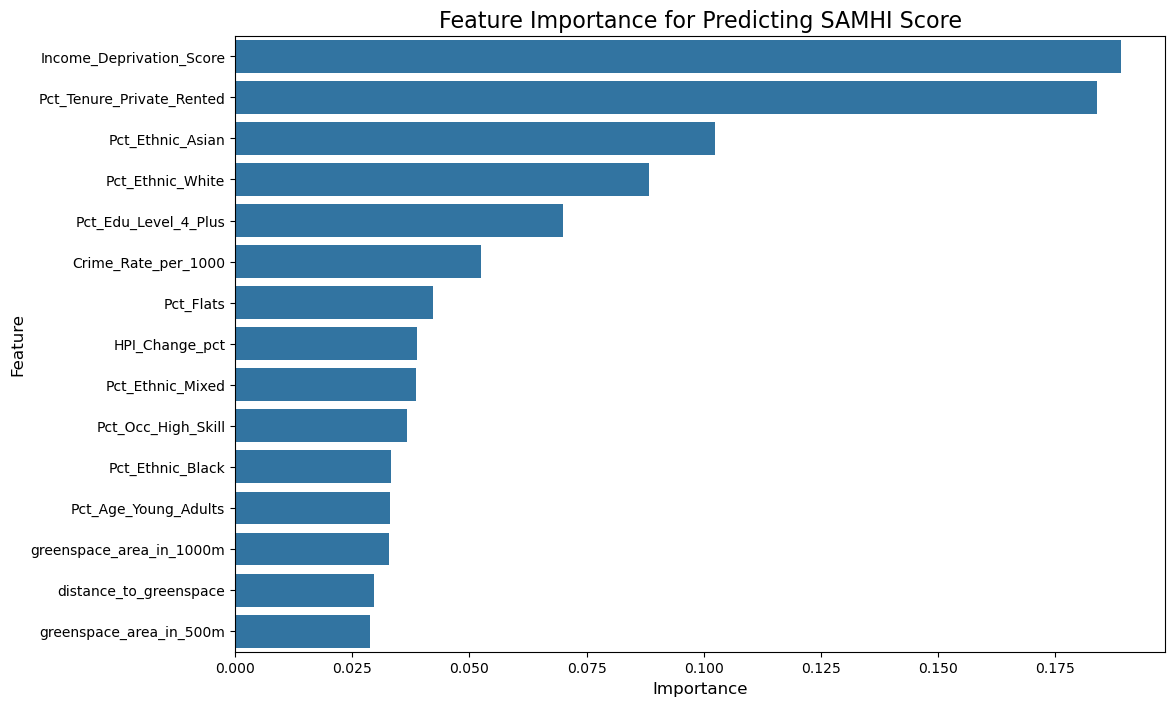

In [30]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance for Predicting SAMHI Score', fontsize=16)
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import pandas as pd

# --- 1. Define your base features and target ---
# These are all your control variables that will be in every model
base_features = [
    'Pct_Edu_Level_4_Plus',
    'Pct_Tenure_Private_Rented',
    'Pct_Occ_High_Skill',
    'Pct_Age_Young_Adults',
    'Pct_Ethnic_White',
    'Pct_Ethnic_Asian',
    'Pct_Ethnic_Black',
    'Pct_Ethnic_Mixed',
    'Total_Crimes_12m',
    'HPI_Change_pct',
    'Income_Deprivation_Score',
    'Pct_Flats'
]
target = 'SAMHI_Score'

# --- 2. Define the green space features you want to test ---
greenspace_features_to_test = [
    'distance_to_greenspace',
    'greenspace_area_in_500m',
    'greenspace_area_in_1000m'
]

# --- 3. Loop through, train a model for each, and store the results ---
model_performance = {}

print("--- Testing Green Space Features ---")
for gs_feature in greenspace_features_to_test:
    print(f"Training model with feature: {gs_feature}")
    
    # Create the full feature list for this model
    current_features = base_features + [gs_feature]
    
    # Prepare the data
    X = analysis_gdf[current_features]
    y = analysis_gdf[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    
    # Train the model
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    # Evaluate and store the R-squared score
    y_pred = rf.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    model_performance[gs_feature] = r2

# --- 4. Report the results ---
print("\n--- Model Performance Comparison ---")
performance_df = pd.DataFrame.from_dict(model_performance, orient='index', columns=['R-squared'])
print(performance_df.sort_values(by='R-squared', ascending=False))

--- Testing Green Space Features ---
Training model with feature: distance_to_greenspace
Training model with feature: greenspace_area_in_500m
Training model with feature: greenspace_area_in_1000m

--- Model Performance Comparison ---
                          R-squared
greenspace_area_in_500m    0.504815
distance_to_greenspace     0.502588
greenspace_area_in_1000m   0.501705



--- Generating Partial Dependence Plots ---


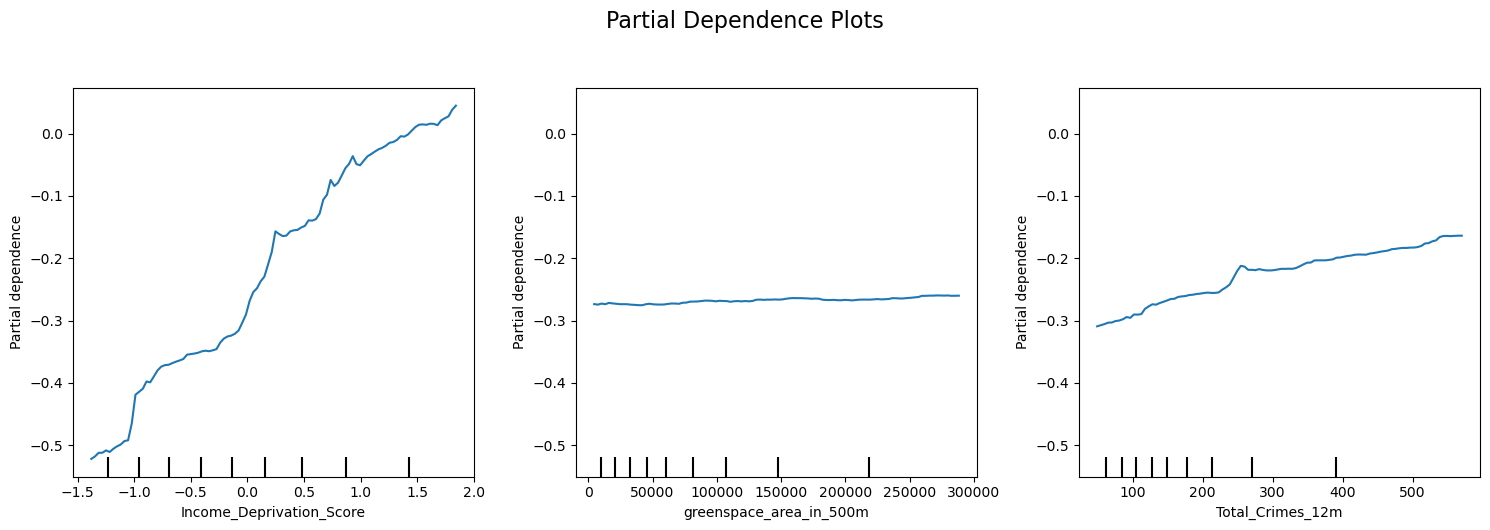

In [32]:
from sklearn.inspection import PartialDependenceDisplay

# --- 1. Train your FINAL model ---
# Use the single best green space feature you identified above
# For this example, let's assume 'greenspace_area_in_1000m' was the best.
final_features = base_features + ['greenspace_area_in_500m']

X = analysis_gdf[final_features]
y = analysis_gdf[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

final_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
final_model.fit(X_train, y_train)


# --- 2. Create Partial Dependence Plots ---
# This shows the relationship between a feature and the predicted outcome,
# after averaging out the effects of all other features.
print("\n--- Generating Partial Dependence Plots ---")

# Define the features you want to plot (usually the most important ones)
features_to_plot = ['Income_Deprivation_Score', 'greenspace_area_in_500m', 'Total_Crimes_12m']

# Create the plot
fig, ax = plt.subplots(figsize=(15, 5), ncols=len(features_to_plot))
fig.suptitle('Partial Dependence Plots', size=16, y=1.05)

display = PartialDependenceDisplay.from_estimator(
    final_model,
    X_train,
    features_to_plot,
    ax=ax
)
plt.tight_layout()
plt.show()

In [53]:
import shap

# --- 1. Train your final model (using the full or RFE-selected feature set) ---
final_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
final_model.fit(X_train, y_train)

# --- 2. Create a SHAP Explainer ---
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

# --- 3. Explain a Single Prediction ---
# Let's look at the first LSOA in your test set
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test.iloc[0,:])